![Banner](../images/09_01_banner_rs_banner.png)


# Raster and Vector Data Essentials

Almost every remote sensing project repeats the same core operations: read a raster, check its metadata, put it in the right coordinate system, cut it to a study area, combine tiles, summarise it over polygons, and save the result in a format others can use.


## Overview

This module works through each one on real data with `geolattice.rsense`.


## Core concepts

### Learning objectives

1. Inspect raster metadata: bands, data type, no-data, CRS, transform, resolution and bounds.
2. Choose between GeoTIFF/COG, NetCDF, Zarr and HDF, and convert between them.
3. Reproject rasters, assign a missing CRS, choose resampling methods correctly, and
   understand projection distortion.
4. Clip, mask and read windows of large rasters.
5. Mosaic adjacent tiles.
6. Combine rasters and vectors: point extraction, zonal statistics and rasterization.
7. Make natural- and false-colour composites with appropriate contrast stretches.

### Data

Dataset are available for download in [GeoLattice Data Folder](https://www.dropbox.com/scl/fo/58n9t8sewax7pffrroxd3/AIWTrjKzklRedtYx0mczwcc?rlkey=0fat0am1b0aai5pieqyx0633j&dl=0). Most cover **Onondaga County, New York** (Syracuse and Onondaga Lake), which lets us combine them.

| Source | Used for |
|---|---|
| `/LC08_20150706_subset/multi_band.tif` and its `*_MTL.txt` | Landsat 8 OLI Level-1 bands 2-5 (DN) over Onondaga County, 2015-07-16 (EPSG:32618, 30 m) |
| `/LC08_20150706_subset/DEM_TILES/` | Four elevation tiles covering the county (EPSG:4326, ~120 m) |
| `/data_remote_sensing/Sentinel_2/B2-B12.tif` | Sentinel-2 reflectance × 10,000 near Buffalo, NY; no CRS stored (UTM 17N, 10 m) |
| `/vector_data/USA/NY_County_GCS.shp` | New York county boundaries (EPSG:4326) |

### Contents

1. Setup
2. Reading rasters and inspecting metadata
3. Raster formats: COG, NetCDF, Zarr and HDF
4. Coordinate reference systems and reprojection
5. Clipping, masking and windowed reads
6. Mosaicking
7. Raster algebra: indices and terrain
8. Vector-raster interaction
9. Visualization and contrast stretching
10. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [ ]:
# Setup for raster and vector essentials.
#
# 1. Show plots in the notebook and hide noisy UserWarnings.
# 2. Import the stack this module uses: NumPy, pandas, xarray, GeoPandas,
#    rasterio, matplotlib, and Shapely's box (a rectangle from four coordinates).
# 3. Import geolattice.rsense as rs.
# 4. Silence harmless GDAL notices about TIFF tags, turn the grid off on maps,
#    and create an outputs/ folder for files this notebook writes.

%matplotlib inline
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import geopandas as gpd  # vector data
import rasterio  # raster reading and writing
import matplotlib.pyplot as plt  # figures
from shapely.geometry import box  # rectangle geometry

import geolattice  # GeoLattice
import geolattice.rsense as rs  # GeoLattice remote sensing subpackage

rasterio.Env(CPL_LOG="/dev/null").__enter__()        # silence harmless GDAL TIFF-tag notices
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})  # figure resolution
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)  # folder for the files written in this notebook
# versions and backend
print("geolattice", geolattice.__version__, "| geolattice.rsense", rs.__version__, "| backend:", rs.get_backend())

geolattice 0.3.9 | geolattice.rsense 0.2.0.dev0 | backend: cpu


In [ ]:
# Point at the tutorial files and confirm each one is on disk.
#
# The later sections reuse the same Onondaga County example:
#   - a 4-band Landsat 8 GeoTIFF and its MTL metadata file
#   - four DEM tiles that will be mosaicked
#   - one Sentinel-2 red band
#   - a shapefile of New York counties
# Printing the size is a quick check that the path is right before any analysis.

DATA = Path("../../../../Data")
RS = DATA / "00_shared" / "data_remote_sensing"  # remote sensing sample data
L8_DIR = RS / "LC08_20150706_subset"  # the Landsat 8 subset folder
L8_FILE = L8_DIR / "multi_band.tif"  # multi-band Landsat GeoTIFF
L8_MTL = L8_DIR / "LC08_L1TP_015030_20150716_20170226_01_T1_MTL.txt"  # its metadata (MTL) file
DEM_TILES = sorted((L8_DIR / "DEM_TILES").glob("Onondaga_DEM*.TIF"))  # DEM tiles of Onondaga County
S2_DIR = RS / "Sentinel_2"  # Sentinel-2 bands
COUNTIES = DATA / "00_shared" / "vector_data" / "USA" / "NY_County_GCS.shp"  # New York county boundaries
for p in [L8_FILE, L8_MTL, *DEM_TILES, S2_DIR / "B4.tif", COUNTIES]:  # every input file
    print(f"{p.relative_to(DATA)}  ({p.stat().st_size / 1e6:.1f} MB)")  # its path and size

data_remote_sensing/LC08_20150706_subset/multi_band.tif  (25.4 MB)
data_remote_sensing/LC08_20150706_subset/LC08_L1TP_015030_20150716_20170226_01_T1_MTL.txt  (0.0 MB)
data_remote_sensing/LC08_20150706_subset/DEM_TILES/Onondaga_DEM0.TIF  (0.2 MB)
data_remote_sensing/LC08_20150706_subset/DEM_TILES/Onondaga_DEM1.TIF  (0.2 MB)
data_remote_sensing/LC08_20150706_subset/DEM_TILES/Onondaga_DEM2.TIF  (0.2 MB)
data_remote_sensing/LC08_20150706_subset/DEM_TILES/Onondaga_DEM3.TIF  (0.1 MB)
data_remote_sensing/Sentinel_2/B4.tif  (0.1 MB)
vector_data/USA/NY_County_GCS.shp  (0.2 MB)


## Reading rasters and inspecting metadata


`rs.read` opens any GDAL-readable raster as a georeferenced `DataArray` with dimensions
(band, y, x). `masked=True` (the default) turns the no-data value into NaN, and `band_names`
labels the bands so later steps can refer to them by name.


In [ ]:
# Read the Landsat multi-band GeoTIFF and give the bands plain names.
#
# rs.read opens the file as an xarray DataArray and keeps the georeferencing.
# band_names replaces "band 1, 2, 3, 4" with blue, green, red and nir, which is
# what the index functions look for later. Displaying the object shows the
# dimensions, coordinates and CRS without printing every pixel.

landsat_dn = rs.read(L8_FILE, band_names=["blue", "green", "red", "nir"])
landsat_dn  # show the DataArray

<xarray.DataArray (band: 4, y: 1853, x: 1630)> Size: 48MB
[12081560 values with dtype=float32]
Coordinates:
  * band         (band) <U5 80B 'blue' 'green' 'red' 'nir'
  * y            (y) float64 15kB 4.792e+06 4.792e+06 ... 4.736e+06 4.736e+06
  * x            (x) float64 13kB 3.779e+05 3.78e+05 ... 4.268e+05 4.268e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  30634
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  8274
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

In [ ]:
# Summarise three different rasters in one table.
#
# describe() pulls the facts you need before trusting a file: how many bands,
# the shape, the in-memory dtype, the no-data flag, the CRS, the pixel size,
# the bounds, and what fraction of pixels are finite (not NaN).
#
# The three columns are the Landsat cube, one DEM tile, and the Sentinel-2 red
# band. squeeze drops a length-1 band axis so a single-band file is 2-D.

def describe(da, name):
    return pd.Series({  # summary of one raster as a table column
        "bands": da.sizes.get("band", 1),
        "rows × cols": f"{da.rio.height} × {da.rio.width}",
        "dtype (in memory)": str(da.dtype),
        "no-data": da.rio.encoded_nodata if da.rio.encoded_nodata is not None else da.rio.nodata,
        "CRS": str(da.rio.crs),
        "resolution": tuple(round(abs(r), 6) for r in da.rio.resolution()),
        "bounds": tuple(round(b, 4) for b in da.rio.bounds()),
        "valid pixels (%)": round(float(np.isfinite(da.values).mean()) * 100, 1),
    }, name=name)

dem_tile = rs.read(DEM_TILES[0]).squeeze("band", drop=True)  # one DEM tile as a 2-D DataArray
s2_red = rs.read(S2_DIR / "B4.tif").squeeze("band", drop=True)  # the Sentinel-2 red band
# the three summaries side by side
pd.concat([describe(landsat_dn, "multi_band.tif"), describe(dem_tile, DEM_TILES[0].name),
           describe(s2_red, "Sentinel_2/B4.tif")], axis=1)

,multi_band.tif,Onondaga_DEM0.TIF,Sentinel_2/B4.tif
bands,4,1,1
rows × cols,1853 × 1630,222 × 267,170 × 210
dtype (in memory),float32,float32,float32
no-data,-339999995214436424907732413799364296704.0,-340282306073709652508363335590014353408.0,-339999995214436424907732413799364296704.0
CRS,EPSG:32618,EPSG:4326,None
resolution,"(30.0, 30.0)","(0.001133, 0.001133)","(10.0, 10.0)"
bounds,"(377925.0, 4736175.0, 426825.0, 4791765.0)","(-76.5001, 42.7714, -76.1976, 43.0229)","(677770.0, 4762370.0, 679870.0, 4764070.0)"
valid pixels (%),77.1,71.1,100.0


Things to notice:

- **Landsat** (`multi_band.tif`) stores DNs as `float32`, with the most negative float32
  value (about −3.4 × 10³⁸) as no-data. After masking, 77% of pixels are valid: the scene was
  clipped to the county outline, and everything outside it is no-data.
- **The DEM tile** is in geographic coordinates (degrees). Only 71% of its pixels are valid
  for the same reason: it is clipped to the county.
- **The Sentinel-2 band has no CRS.** Its coordinates are numbers without a reference system,
  so it cannot be overlaid on anything until we assign one (the *Coordinate reference systems and reprojection* section).
- The three files use **three different CRS situations** and pixel sizes. Before combining
  them we must bring them onto a common grid.


In [ ]:
# Peek at how each GeoTIFF is stored on disk.
#
# The in-memory array hides details that matter for fast or cloud reads:
# the driver, the on-disk dtype, whether the file is tiled, the compression,
# the overview (pyramid) levels, and any TIFF tags. rasterio.open reads only
# that header. Overviews are the reduced-resolution copies a COG uses when you
# zoom out.

for path in [L8_FILE, DEM_TILES[0], S2_DIR / "B4.tif"]:
    with rasterio.open(path) as src:  # open the file
        # format, data type and tiling of the file
        print(f"{path.name:18s} driver {src.driver}, dtype {src.dtypes[0]}, tiled {src.profile.get('tiled')}, "
              f"compression {src.profile.get('compress')}, overviews {src.overviews(1)}, tags {src.tags()}")

multi_band.tif     driver GTiff, dtype float32, tiled False, compression lzw, overviews [], tags {'AREA_OR_POINT': 'Area'}
Onondaga_DEM0.TIF  driver GTiff, dtype float32, tiled True, compression lzw, overviews [], tags {'DataType': 'Generic', 'AREA_OR_POINT': 'Area'}
B4.tif             driver GTiff, dtype float32, tiled False, compression lzw, overviews [], tags {}


The Landsat bands are still raw **digital numbers (DN)**. As in notebook 09_01_00, the MTL metadata
file converts them to top-of-atmosphere reflectance, which is what indices need:


In [ ]:
# Convert Landsat digital numbers to top-of-atmosphere reflectance.
#
# The pixels in the file are DNs, not reflectance. The MTL text file stores the
# gain, bias and sun elevation that turn DN into TOA reflectance:
#     reflectance = (M * DN + A) / sin(sun elevation)
#
# 1. parse_mtl reads that text file into a dictionary.
# 2. toa_reflectance applies the formula to each band. Band numbers follow the
#    Landsat 8 naming (blue is band 2, nir is band 5).
# 3. concat stacks the four bands back into one cube and copies the CRS.
# 4. The median of each band is a quick sanity check: TOA reflectance of land
#    should sit between 0 and 1, not in the thousands.

mtl = rs.optical.parse_mtl(L8_MTL)
# acquisition date, cloud cover and sun angle
print("Acquired", mtl["DATE_ACQUIRED"], "| cloud cover", mtl["CLOUD_COVER"], "% | sun elevation",
      round(mtl["SUN_ELEVATION"], 1), "°")
band_no = {"blue": 2, "green": 3, "red": 4, "nir": 5}  # band name -> Landsat 8 band number
# DN -> top-of-atmosphere reflectance, band by band
landsat = xr.concat([rs.optical.toa_reflectance(landsat_dn.sel(band=n), mtl[f"REFLECTANCE_MULT_BAND_{b}"],
                                                mtl[f"REFLECTANCE_ADD_BAND_{b}"], mtl["SUN_ELEVATION"])
                     for n, b in band_no.items()], dim="band").rio.write_crs(landsat_dn.rio.crs)
# median reflectance of each band
landsat.to_dataset(dim="band").median().to_pandas().round(3).rename("median TOA reflectance").to_frame().T

Acquired 2015-07-16 | cloud cover 0.08 % | sun elevation 62.1 °


,blue,green,red,nir
median TOA reflectance,0.094,0.084,0.052,0.38


## Raster formats: COG, NetCDF, Zarr and HDF


| Format | Best for | Notes |
|---|---|---|
| **GeoTIFF / Cloud-Optimized GeoTIFF (COG)** | Single images, sharing, web maps | A COG is a tiled GeoTIFF with internal overviews, so software can read just the part it needs over HTTP. `rs.write` writes COGs by default. |
| **NetCDF** | Climate and gridded science data, time series | Self-describing, CF conventions; one file holds many variables. |
| **Zarr** | Large multi-dimensional cubes, cloud storage | Chunked and parallel; ideal for Dask and object storage. |
| **HDF4 / HDF5** | NASA products (MODIS, GEDI, ICESat-2) | Many layers per file; read them with `rs.core.read_hdf`. |
| **JPEG2000 (JP2)**, **SAFE** | Sentinel-2/Sentinel-1 distribution | `rs.core.read_safe` indexes a `.SAFE` folder. |

Let's write the Landsat NIR reflectance band in three formats and compare file sizes and
read-back fidelity. The source GeoTIFF is striped (not tiled) and has no overviews, so it is
not cloud-optimized; `rs.write` fixes that.


In [ ]:
# Write the NIR band three ways and check that each round-trip is exact.
#
# The same array can live in a Cloud Optimized GeoTIFF, a NetCDF file, or a
# Zarr store. What changes is the on-disk layout, not the values.
#
# 1. Cast NIR to float32 and write all three formats.
# 2. size_mb handles both a single file and a Zarr directory (many small files).
# 3. Read each format back and compare values (NaNs count as equal) and the EPSG code.

nir = landsat.sel(band="nir", drop=True).astype("float32")

rs.write(nir, OUT / "nir_cog.tif")                                  # COG, DEFLATE compression
nir.to_dataset(name="nir").to_netcdf(OUT / "nir.nc")  # save as NetCDF
rs.core.write_zarr(nir.rename("nir"), OUT / "nir.zarr")  # save as Zarr

def size_mb(p):  # size of a file or folder (MB)
    p = Path(p)  # as a Path
    # sum of all files when it is a folder
    return (sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size) / 1e6

back_cog = rs.read(OUT / "nir_cog.tif").squeeze("band", drop=True)  # read the COG back
back_nc = rs.core.read_netcdf(OUT / "nir.nc", "nir")  # read the NetCDF back
back_zarr = rs.core.read_zarr(OUT / "nir.zarr")["nir"]  # read the Zarr back
pd.DataFrame({  # size of each format and whether the data survived the round trip
    "size (MB)": [nir.nbytes / 1e6, size_mb(OUT / "nir_cog.tif"), size_mb(OUT / "nir.nc"), size_mb(OUT / "nir.zarr")],
    "identical values": ["n/a", bool(np.allclose(back_cog, nir, equal_nan=True)),
                         bool(np.allclose(back_nc, nir, equal_nan=True)), bool(np.allclose(back_zarr, nir, equal_nan=True))],
    "CRS preserved": ["n/a", back_cog.rio.crs.to_epsg(), back_nc.rio.crs.to_epsg(), back_zarr.rio.crs.to_epsg()],
}, index=["in memory", "COG", "NetCDF", "Zarr"]).round(2)

,size (MB),identical values,CRS preserved
in memory,12.08,-,-
COG,9.26,True,32618
NetCDF,12.13,True,32618
Zarr,6.97,True,32618


In [ ]:
# Confirm the GeoTIFF written above is actually cloud-optimized.
#
# A COG is tiled (here, square internal blocks) and carries an overview pyramid.
# Those two facts are what let a later reader fetch one window, or a zoomed-out
# view, without scanning the whole file.

with rasterio.open(OUT / "nir_cog.tif") as src:
    # internal block size and overview levels of the COG
    print("COG internal tiling:", src.block_shapes[0], "| overview levels:", src.overviews(1))

COG internal tiling: (512, 512) | overview levels: [2, 4]


All three formats read back identical values and keep the CRS (EPSG:32618). For this
reflectance band, Zarr was the smallest (7.0 MB against 12.1 MB in memory), the COG came next
(9.3 MB), and NetCDF was written uncompressed (12.1 MB) because no compression was requested.
Floating-point reflectance compresses less than integer DNs or elevations would. The COG is
internally tiled in 512 × 512 blocks with overviews at 2× and 4×; the original
`multi_band.tif` had neither.


## Coordinate reference systems and reprojection


A **CRS** defines how coordinates relate to places on Earth.

- **Geographic** CRSs (EPSG:4326) use degrees of latitude and longitude. A degree of
  longitude shrinks toward the poles, so they are poor for measuring distances and areas.
- **Projected** CRSs such as **UTM** use metres on a flat grid with small distortion within each 6° zone.
- **Web Mercator** (EPSG:3857) is designed for web maps; it stretches distances and areas by
  $1/\cos(\text{latitude})$.

`rs.core.estimate_utm_crs` finds the right UTM zone; `rs.reproject` warps a raster. Our three
rasters show the three situations you meet in practice: Landsat is already in UTM, the DEM is
geographic, and the Sentinel-2 files have no CRS at all.


In [ ]:
# Pick a projected CRS, and see what Web Mercator does to pixel size.
#
# 1. estimate_utm_crs suggests a UTM zone from the data's own footprint.
#    The Landsat scene and the DEM tile can land in the same zone.
# 2. The DEM is stored in degrees. At Syracuse's latitude, one degree of
#    longitude is shorter than one degree of latitude, so a "square" geographic
#    pixel is not square on the ground.
# 3. Reprojecting the 30 m Landsat pixels to EPSG:3857 (Web Mercator) inflates
#    the reported pixel size by about 1/cos(latitude). Those units are Mercator
#    metres, not ground metres.

lat = 43.05                                                           # Syracuse
# UTM zone for the Landsat scene
print(f"UTM zone suggested for the Landsat scene: EPSG:{rs.core.estimate_utm_crs(landsat)}")
# UTM zone for the DEM tile
print(f"UTM zone suggested for the DEM tile:      EPSG:{rs.core.estimate_utm_crs(dem_tile)}")
# ground size of a geographic (degree) pixel at this latitude
print(f"One DEM pixel: {abs(dem_tile.rio.resolution()[0]) * 111_320 * np.cos(np.radians(lat)):.0f} m east-west × "
      f"{abs(dem_tile.rio.resolution()[1]) * 110_574:.0f} m north-south at {lat}°N")

landsat_wm = rs.reproject(landsat, "EPSG:3857", resampling="bilinear")  # Landsat in Web Mercator
# Web Mercator enlarges distances by 1 / cos(latitude)
print(f"\nWeb Mercator scale factor at {lat}°N: {1 / np.cos(np.radians(lat)):.3f}")
# resolution after reprojection
print("Landsat reprojected to Web Mercator: resolution", tuple(round(abs(r), 1) for r in landsat_wm.rio.resolution()),
      "'metres' for 30 m ground pixels")

UTM zone suggested for the Landsat scene: EPSG:32618
UTM zone suggested for the DEM tile:      EPSG:32618
One DEM pixel: 92 m east-west × 125 m north-south at 43.05°N



Web Mercator scale factor at 43.05°N: 1.368
Landsat reprojected to Web Mercator: resolution (41.1, 41.1) 'metres' for 30 m ground pixels


Both rasters belong in UTM zone 18N, which the Landsat file already uses. The DEM's "square"
0.00113° pixels are rectangles on the ground: 92 m east-west but 125 m north-south at 43°N,
because meridians converge toward the pole. In Web Mercator the same 30 m Landsat pixels
become 41.1 "metres" wide (30 × 1.368). Any area measured in EPSG:3857 here would be
overstated by a factor of 1.37² ≈ 1.87.

**Assigning a missing CRS.** The Sentinel-2 files store coordinates but no CRS. Reprojecting
or overlaying them is impossible until we *assign* the CRS, which must come from
documentation (here, the metadata of the ground-truth shapefile says UTM zone 17N).
Assigning (`write_crs`) only labels the coordinates; reprojecting (`rs.reproject`) changes them.


In [ ]:
# Fix a missing CRS, then check the scene really sits in western New York.
#
# This Sentinel-2 GeoTIFF was saved without a CRS tag, so rio.crs is None.
# write_crs only attaches the label EPSG:32617 (UTM zone 17N). It does not move
# the pixels. Reprojecting to longitude/latitude afterwards is the check: the
# centre should fall near Buffalo, not on the equator or in another UTM zone.

print("CRS as read:", s2_red.rio.crs)
s2_red = s2_red.rio.write_crs("EPSG:32617")  # attach the correct CRS (overwrites a missing or wrong one)
lon_lat = rs.reproject(s2_red, "EPSG:4326")  # reproject to longitude/latitude
print("After write_crs:", s2_red.rio.crs, "| centre:",  # the CRS and the image centre
      tuple(round(float(v), 4) for v in (lon_lat.x.mean(), lon_lat.y.mean())), "(lon, lat)")

CRS as read: None
After write_crs: EPSG:32617 | centre: (-78.8061, 43.0007) (lon, lat)


**Choosing a resampling method** matters:

- `nearest`: keeps original values; required for **categorical** data (land cover classes, QA bits, masks).
- `bilinear` / `cubic`: smooth interpolation for **continuous** data (reflectance, elevation).
- `average`: correct when **aggregating** to coarser pixels (e.g. 10 m → 500 m).

The example classifies the DEM into three elevation zones (a land-cover-like map) and
reprojects it to UTM at 30 m. Bilinear resampling invents classes that don't exist.


Unique values, nearest : [1. 2. 3.]
Unique values, bilinear: 8282 distinct values (invalid classes!)


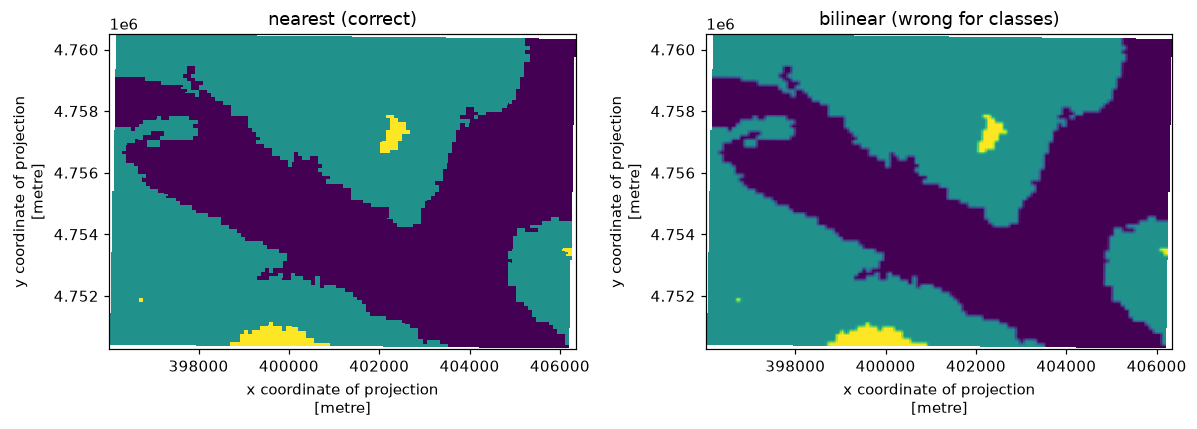

In [ ]:
# Show why a categorical raster must use nearest-neighbour resampling.
#
# Elevation is a continuous number, so averaging neighbouring pixels (bilinear)
# is reasonable. A class code is not. Bilinear resampling invents values such
# as 1.4, which is not a class.
#
# 1. Mosaic the DEM tiles and bin elevation into classes 1, 2 and 3.
# 2. Reproject a small window to UTM at 30 m, once with nearest and once with bilinear.
# 3. Nearest keeps the original integers. Bilinear produces many fractional values.

dem_all = rs.mosaic([rs.read(p).squeeze("band", drop=True) for p in DEM_TILES])   # Section 6 explains mosaics
# three elevation classes, NaN where the DEM has no data
classes = xr.where(dem_all > 400, 3, xr.where(dem_all > 250, 2, 1)).where(dem_all.notnull())
# as floats with a CRS, and a small window
classes = classes.astype("float32").rio.write_crs(4326).isel(y=slice(250, 330), x=slice(200, 310))
near = rs.reproject(classes, 32618, resolution=30, resampling="nearest")  # reprojected with nearest neighbour
# reprojected with bilinear interpolation
bil = rs.reproject(classes, 32618, resolution=30, resampling="bilinear")
# nearest keeps the class values
print("Unique values, nearest :", np.unique(near.values[np.isfinite(near.values)])[:10])
# bilinear invents values between classes
print("Unique values, bilinear:", np.unique(bil.values[np.isfinite(bil.values)]).size, "distinct values (invalid classes!)")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # two panels
# nearest result
near.plot(ax=axes[0], cmap="viridis", add_colorbar=False); axes[0].set_title("nearest (correct)")
# bilinear result
bil.plot(ax=axes[1], cmap="viridis", add_colorbar=False); axes[1].set_title("bilinear (wrong for classes)")
plt.tight_layout(); plt.show()  # arrange and draw

To combine rasters, put them on **the same grid** (CRS, resolution, extent and alignment).
`reproject_match` warps one raster onto another's grid in a single step. Here the DEM is
matched to the 30 m Landsat grid so pixels line up one-to-one.


In [ ]:
# Put the DEM onto the Landsat grid so the two layers share every pixel.
#
# reproject_match warps the DEM to the Landsat CRS, resolution and extent.
# Bilinear is appropriate because elevation is continuous. The transforms are
# then identical, which means NDVI and elevation can be paired pixel by pixel
# with no further resampling.

from rasterio.enums import Resampling
# resample the DEM onto the Landsat grid
dem_on_landsat = dem_all.astype("float32").rio.reproject_match(landsat, resampling=Resampling.bilinear)
print("Landsat grid:", landsat.shape[1:], "| DEM matched:", dem_on_landsat.shape,  # both grids now match
      "| same transform:", landsat.rio.transform() == dem_on_landsat.rio.transform())

Landsat grid: (1853, 1630) | DEM matched: (1853, 1630) | same transform: True


Matching a 120 m DEM to a 30 m grid does not add detail: bilinear interpolation only
smooths between the original elevations. Resampling changes the grid, never the information
content.

## Clipping, masking and windowed reads

**Clipping** cuts a raster to a polygon; **masking** sets pixels outside it (or failing a
condition) to NaN; **windowed reading** loads only a block of a large file. Our study areas
are the Onondaga County boundary from the New York counties layer and a box around the city
of Syracuse and Onondaga Lake.


In [ ]:
# Load county polygons and a simple box, then clip rasters to them.
#
# 1. Read the New York county shapefile and keep Onondaga County.
# 2. Build an AOI rectangle around Syracuse and Onondaga Lake. box() takes
#    (minx, miny, maxx, maxy) in longitude/latitude.
# 3. Compare the county area computed from the geometry (after projecting to
#    UTM metres) with the square-mile column already in the attribute table.
# 4. rs.clip cuts the DEM to the county and to the AOI, and cuts Landsat to
#    the AOI after the box is reprojected into the Landsat CRS.

counties = gpd.read_file(COUNTIES)
onondaga = counties[counties["COUNTY"] == "Onondaga County"]  # the Onondaga County polygon
aoi = gpd.GeoDataFrame({"name": ["Syracuse and Onondaga Lake"]},  # a box around Syracuse and Onondaga Lake
                       geometry=[box(-76.30, 42.98, -76.05, 43.15)], crs=4326)
print(f"Onondaga County: {onondaga.to_crs(32618).area.iloc[0] / 1e6:,.0f} km² "  # county area in km²
      f"(attribute table: {onondaga['SQUARE_MIL'].iloc[0]:.1f} mi² = {onondaga['SQUARE_MIL'].iloc[0] * 2.58999:,.0f} km²)")

dem_county = rs.clip(dem_all, onondaga)  # DEM clipped to the county outline
dem_aoi = rs.clip(dem_all, aoi)  # DEM clipped to the AOI box
landsat_aoi = rs.clip(landsat, aoi.to_crs(landsat.rio.crs))  # Landsat clipped to the AOI (in Landsat's CRS)
# sizes of the clipped rasters
print("DEM clipped to county:", dem_county.shape, "| DEM clipped to AOI:", dem_aoi.shape,
      "| Landsat clipped to AOI:", landsat_aoi.shape)

Onondaga County: 2,095 km² (attribute table: 807.8 mi² = 2,092 km²)
DEM clipped to county: (442, 534) | DEM clipped to AOI: (150, 220) | Landsat clipped to AOI: (4, 639, 687)


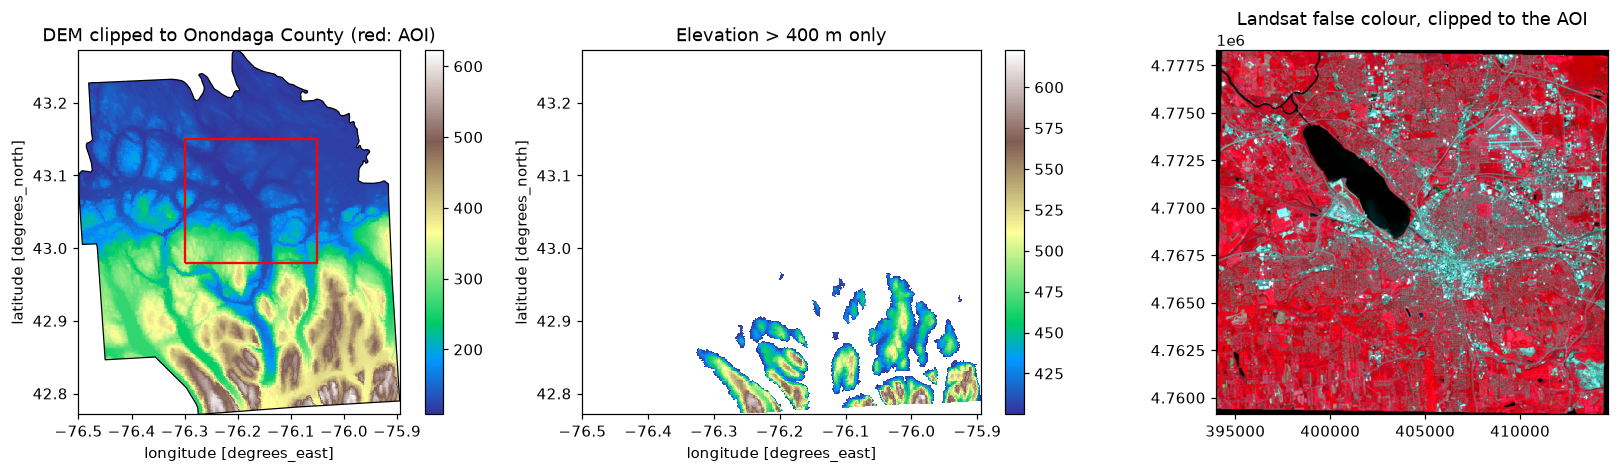

In [ ]:
# Draw the clipped DEM, a conditional mask, and a false-colour Landsat view.
#
# where(elevation > 400) keeps highland pixels and sets the rest to NaN, so the
# middle map shows only the higher ground. The right panel is NIR-red-green:
# vegetation comes out red. The county outline and the red AOI box sit on the
# left map so you can see how the two clip geometries relate.

mask_high = dem_county.where(dem_county > 400)            # mask by a condition
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))  # three panels
# county DEM and outline
dem_county.plot(ax=axes[0], cmap="terrain"); onondaga.boundary.plot(ax=axes[0], color="k", lw=0.8)
# AOI outline and title
aoi.boundary.plot(ax=axes[0], color="red"); axes[0].set_title("DEM clipped to Onondaga County (red: AOI)")
mask_high.plot(ax=axes[1], cmap="terrain"); axes[1].set_title("Elevation > 400 m only")  # only the high ground
# Landsat false colour of the AOI
rs.viz.plot_rgb(landsat_aoi.to_dataset(dim="band"), ("nir", "red", "green"), ax=axes[2],
                title="Landsat false colour, clipped to the AOI")
plt.tight_layout(); plt.show()  # arrange and draw

The county area computed from the polygon in UTM (2,095 km²) matches the attribute table
(807.8 mi² = 2,092 km²) to within 0.2%, a good check that the reprojection is right. The DEM
shows the county's two landscapes: the flat Ontario lake plain in the north (110-150 m),
around Onondaga Lake and Syracuse, and the dissected Appalachian Plateau in the south, where
hills above 400 m are cut by deep north-south glacial valleys. In the false-colour clip, the
city and its roads are cyan-grey, Onondaga Lake is black, and Syracuse's airport is visible to
the northeast.

For files larger than memory, read only what you need. `rasterio` windows load a pixel block
directly, and `rs.read(..., chunks=...)` gives a lazy array where slicing touches only the
required chunks.


In [ ]:
# Read only the window you need, instead of the whole Landsat band.
#
# 1. Project the AOI into the Landsat CRS and clip the in-memory NIR band to it.
#    clip_box snaps the request to whole pixels.
# 2. from_bounds turns those map bounds into a rasterio window (pixel rows and
#    columns). read(4, window=...) pulls band 4 of the file, which is NIR,
#    and only that block.
# 3. The printed sizes show the I/O saving. allclose confirms the window matches
#    the in-memory clip, including NaNs.

from rasterio.windows import from_bounds

bounds_utm = aoi.to_crs(landsat.rio.crs).total_bounds  # AOI bounds in Landsat's CRS
clip_dn = landsat_dn.sel(band="nir").rio.clip_box(*bounds_utm)          # in-memory clip, snapped to pixels
with rasterio.open(L8_FILE) as src:  # open the file
    # pixel window of the clipped area
    win = from_bounds(*clip_dn.rio.bounds(), transform=src.transform).round_offsets().round_lengths()
    block = src.read(4, window=win, masked=True).filled(np.nan)            # band 4 of the file = NIR
    print("Window:", win, "→ array", block.shape,  # the window and the array read from it
          f"({block.nbytes / 1e6:.1f} MB instead of {src.width * src.height * 4 / 1e6:.1f} MB per band)")
# reading the window gives the same pixels as clipping
print("Matches the clip:", block.shape == clip_dn.shape and np.allclose(block, clip_dn.values, equal_nan=True))

Window: Window(col_off=535, row_off=449, width=689, height=639) → array (639, 689) (1.8 MB instead of 12.1 MB per band)
Matches the clip: True


## Mosaicking


Large study areas span several scenes or tiles. `rs.mosaic` merges rasters onto one grid,
reprojecting if needed. Where tiles overlap, `first` / `last` give priority by order, while
`min`, `max` or `mean` combine the values. The four Onondaga DEM tiles are adjacent quarters
of the county; we merge them and check the result against the complete county DEM stored
separately in `Data/00_shared/raster_data/USA/Onondaga_DEM.tif`.


Tile shapes: [(222, 267), (222, 267), (221, 267), (221, 267)]
Mosaic shape: (443, 534) | reference shape: (443, 534)
Same grid (to 1e-9°): True | identical values: True


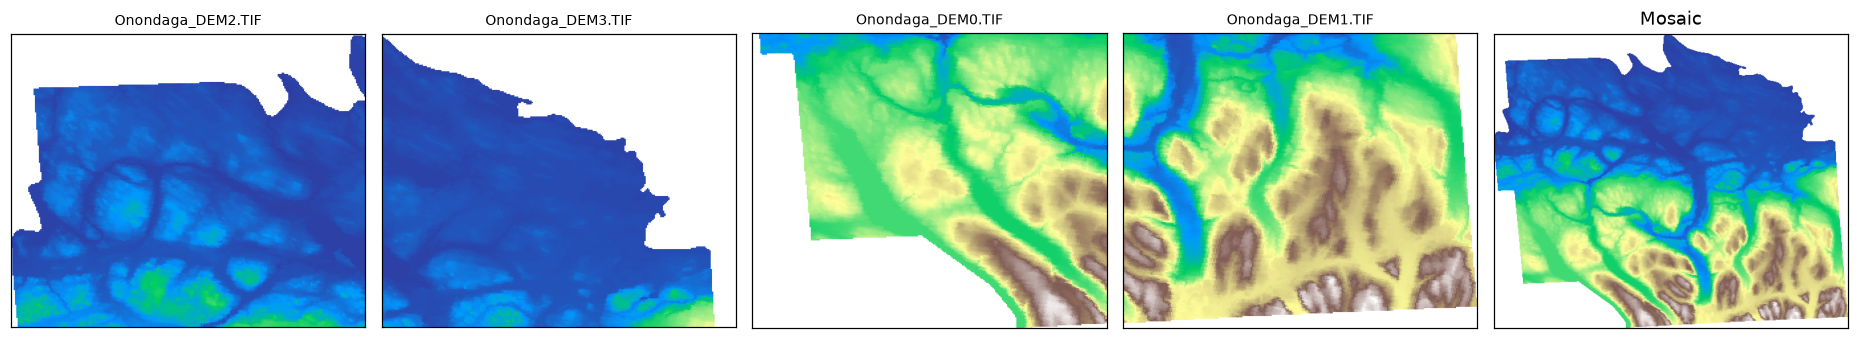

In [ ]:
# Mosaic the four DEM tiles and check the result against a reference file.
#
# rs.mosaic(..., "first") keeps the first tile's value where tiles overlap.
# The reference Onondaga_DEM.tif is the same mosaic prepared ahead of time.
# Comparing the affine transform (to a tiny tolerance) and the values confirms
# the merge did not shift or resample the grid.
#
# The figure shows the tiles in map order: northwest, northeast, southwest,
# southeast: then the merged grid. File order on disk is not map order.

tiles = [rs.read(p).squeeze("band", drop=True) for p in DEM_TILES]
print("Tile shapes:", [t.shape for t in tiles])  # shapes of the four tiles
merged = rs.mosaic(tiles, "first")  # mosaic them, keeping the first value where tiles overlap
# the county DEM shipped as one file
full = rs.read(DATA / "00_shared" / "raster_data" / "USA" / "Onondaga_DEM.tif").squeeze("band", drop=True)
print("Mosaic shape:", merged.shape, "| reference shape:", full.shape)  # shapes of both
# the mosaic is on the same grid as the reference
print("Same grid (to 1e-9°):", np.allclose(tuple(merged.rio.transform())[:6], tuple(full.rio.transform())[:6], atol=1e-9),
      "| identical values:", bool(np.allclose(merged.values, full.values, equal_nan=True)))

fig, axes = plt.subplots(1, 5, figsize=(17, 3.2))  # five panels
order = [2, 3, 0, 1]                                         # show tiles in map order: NW, NE, SW, SE
for a, i in zip(axes[:4], order):  # each tile
    # show it
    a.imshow(tiles[i].values, cmap="terrain", vmin=100, vmax=620); a.set_title(DEM_TILES[i].name, fontsize=9)
axes[4].imshow(merged.values, cmap="terrain", vmin=100, vmax=620); axes[4].set_title("Mosaic")  # the mosaic
for a in axes:  # every panel
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

## Raster algebra: indices and terrain


Band math produces new information layers. `geolattice.rsense` handles band lookup, NaN, division
by zero and GPU execution. Here we compute NDVI from the Landsat reflectance and slope, aspect
and hillshade from the DEM matched to the same grid.


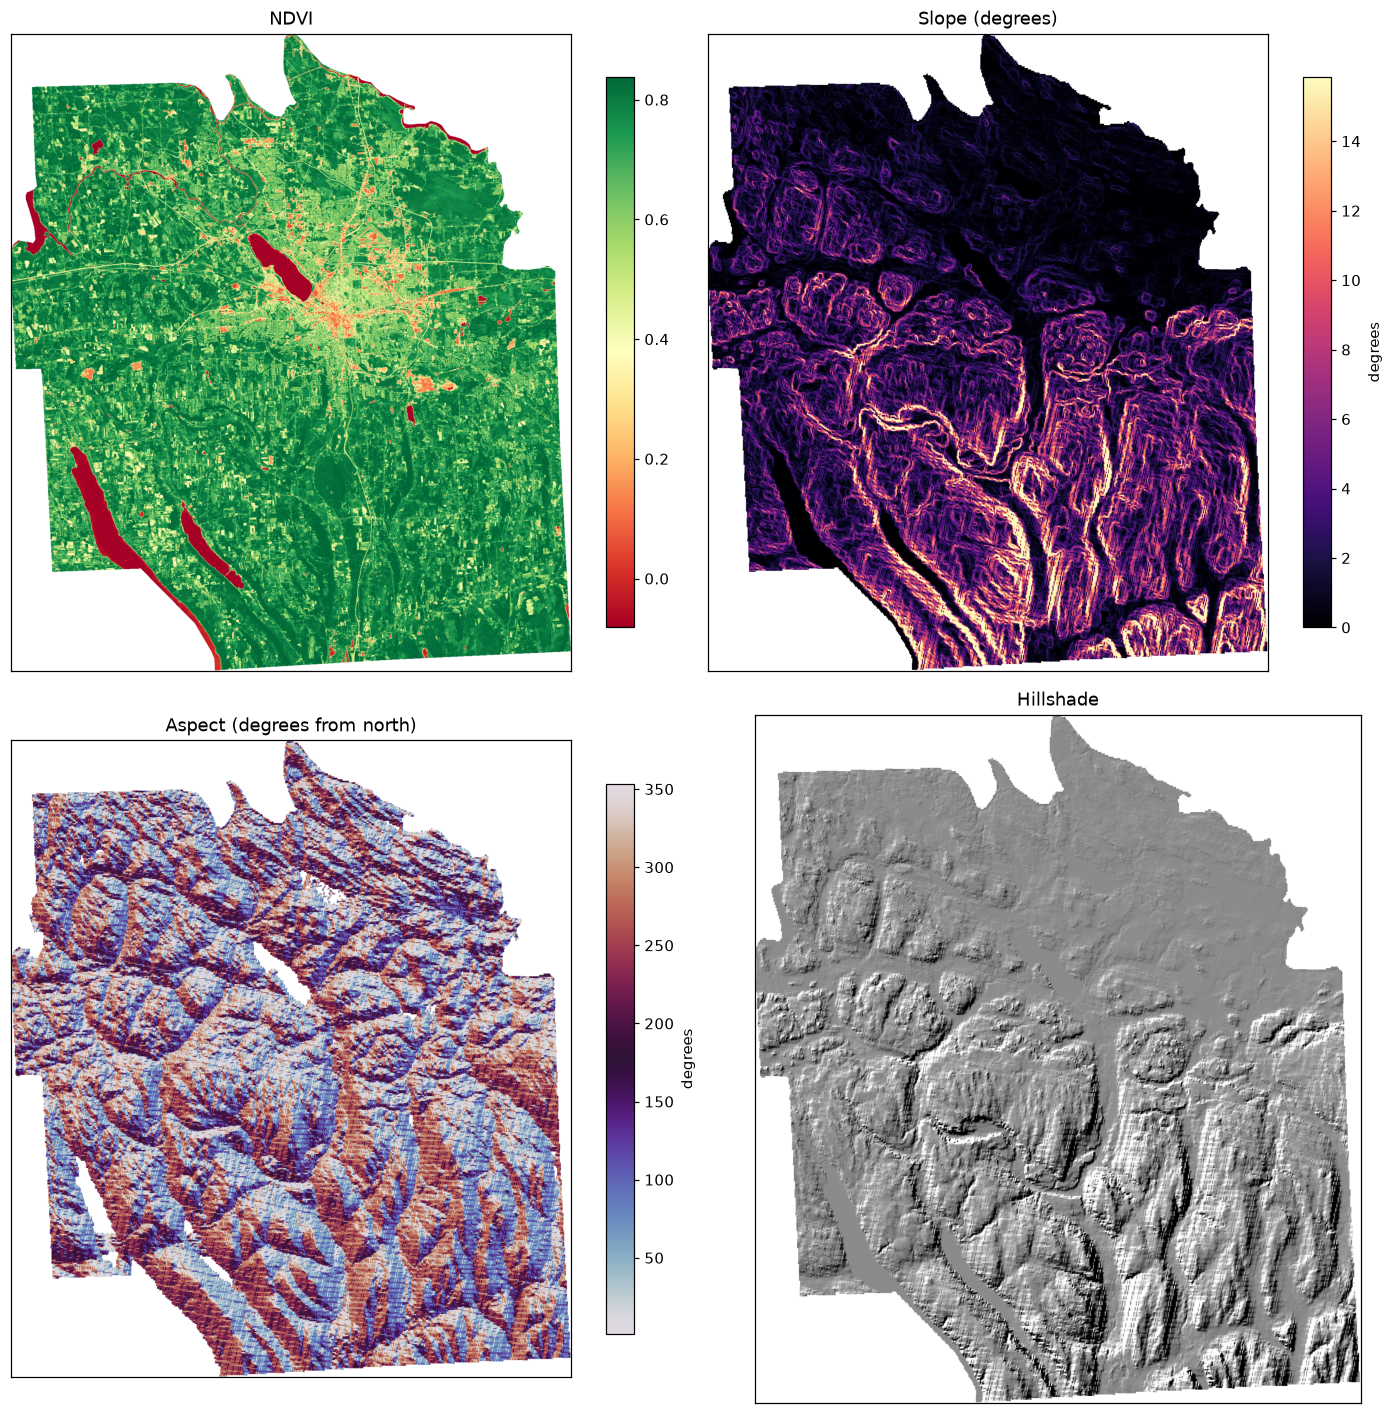

In [ ]:
# Derive NDVI, slope, aspect and hillshade on the shared Landsat grid.
#
# NDVI comes from the optical bands. Slope, aspect and hillshade come from the
# DEM that was warped onto that same grid, so all four maps line up.
# Hillshade uses a sun in the northwest (azimuth 315°) at 45° above the horizon,
# which is the usual choice for a readable shaded relief. The colorbar is turned
# off because hillshade is a display layer, not a measurement to read off a scale.

ls = landsat.to_dataset(dim="band")
ndvi = rs.optical.index(ls, "NDVI")  # NDVI from the Landsat bands
slope = rs.lidar.slope(dem_on_landsat)  # slope from the DEM
aspect = rs.lidar.aspect(dem_on_landsat)  # aspect from the DEM
# hillshade, sun from the north-west at 45 degrees
hill = rs.lidar.hillshade(dem_on_landsat, azimuth=315, altitude=45)

fig, axes = plt.subplots(2, 2, figsize=(13, 13))  # 2 x 2 panels
rs.viz.plot_raster(ndvi, ax=axes[0, 0], cmap="RdYlGn", title="NDVI")  # NDVI
rs.viz.plot_raster(slope, ax=axes[0, 1], cmap="magma", title="Slope (degrees)")  # slope
rs.viz.plot_raster(aspect, ax=axes[1, 0], cmap="twilight", title="Aspect (degrees from north)")  # aspect
rs.viz.plot_raster(hill, ax=axes[1, 1], cmap="gray", title="Hillshade", colorbar=False)  # hillshade
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

NDVI is high almost everywhere in mid-July. The exceptions are water (Onondaga, Otisco and
Skaneateles lakes, and water along the northern county edge), the city of Syracuse, and
roads. Slope picks out the steep sides of the southern valleys.

The hatched, faceted texture in the aspect and hillshade maps is an **artifact**, not
terrain. The DEM pixels are about 92 × 125 m, and bilinear interpolation onto the 30 m grid
creates flat planes between the original elevations. Each plane has a constant aspect and a
uniform shade. Resampling a coarse DEM to a fine grid changes the grid, not the information:
for real 30 m terrain derivatives, use a 30 m (or finer) DEM.


Because both layers are on one grid, they can be analysed together. How does vegetation
greenness change with elevation across Onondaga County?


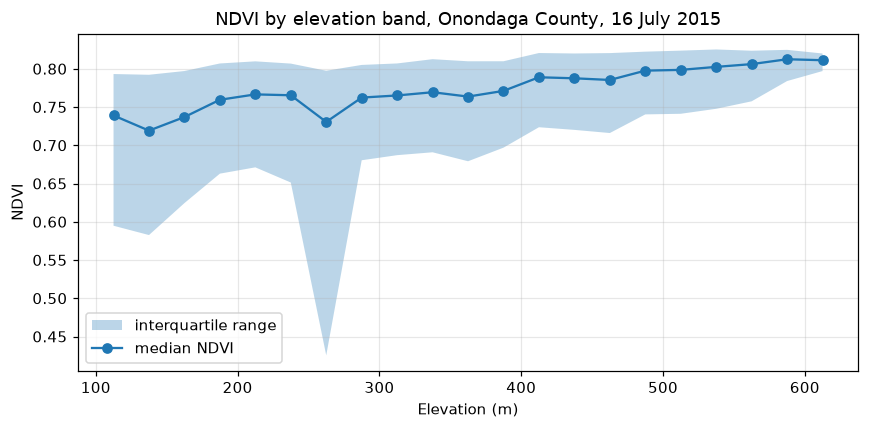

Water pixels (NDVI < 0): 66,064; their elevations cluster at 110 m, 240 m, 263 m (10th, 50th, 90th percentile)
band
(250, 275]    27764
(100, 125]    25962
(225, 250]     9167


,median,q25,q75,pixels
band,,,,
"(100, 125]",0.739,0.595,0.793,517116
"(125, 150]",0.719,0.583,0.792,345209
"(150, 175]",0.737,0.624,0.797,147639
"(175, 200]",0.759,0.663,0.807,123769
"(200, 225]",0.767,0.671,0.810,92784
"(225, 250]",0.765,0.651,0.807,100211
"(250, 275]",0.731,0.425,0.797,129555
"(275, 300]",0.762,0.680,0.805,122546
"(300, 325]",0.765,0.687,0.807,112579


In [ ]:
# Relate NDVI to elevation by binning the paired pixels.
#
# Both rasters share the Landsat grid, so flattening them into two columns does
# not mix locations. dropna removes pixels missing from either layer.
#
# 1. Cut elevation into 25 m bins and, inside each bin, compute the median NDVI,
#    the 25th and 75th percentiles (the interquartile range), and the pixel count.
# 2. Drop bins with 500 pixels or fewer so a thin tail does not dominate the line.
# 3. Plot the median and the shaded interquartile range.
# 4. Separately, look at pixels with NDVI < 0 (water) and where their elevations cluster.

df = pd.DataFrame({"elev": dem_on_landsat.values.ravel(), "ndvi": ndvi.values.ravel()}).dropna()
df["band"] = pd.cut(df.elev, bins=range(100, 650, 25))  # 25 m elevation bands
# NDVI statistics per elevation band
prof = df.groupby("band", observed=True).ndvi.agg(["median", lambda s: s.quantile(0.25), lambda s: s.quantile(0.75), "size"])
prof.columns = ["median", "q25", "q75", "pixels"]  # column names
prof = prof[prof.pixels > 500]  # keep bands with enough pixels
mid = [iv.mid for iv in prof.index]  # middle of each band
fig, ax = plt.subplots(figsize=(8, 4))  # one panel
# interquartile range as a shaded band
ax.fill_between(mid, prof.q25, prof.q75, alpha=0.3, label="interquartile range")
ax.plot(mid, prof["median"], marker="o", label="median NDVI")  # median NDVI
# labels, grid and legend
ax.set_xlabel("Elevation (m)"); ax.set_ylabel("NDVI"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("NDVI by elevation band, Onondaga County, 16 July 2015")  # title
plt.tight_layout(); plt.show()  # arrange and draw
water = df[df.ndvi < 0]  # water pixels
print(f"Water pixels (NDVI < 0): {len(water):,}; their elevations cluster at",  # at which elevations they lie
      ", ".join(f"{v:.0f} m" for v in np.percentile(water.elev, [10, 50, 90])), "(10th, 50th, 90th percentile)")
# the three most common elevation bands of water
print(water.groupby("band", observed=True).size().sort_values(ascending=False).head(3).rename("water pixels").to_string())
prof.round(3)  # show the profile table

NDVI rises with elevation. The median is 0.72-0.74 on the lake plain (100-150 m), which holds
Syracuse, its suburbs and Onondaga Lake, and 0.80-0.81 on the forested plateau tops above
500 m. The spread narrows as well: the lowlands mix built-up land, water and crops, while the
uplands are mostly continuous forest and pasture.

The dip at 250-275 m (median 0.73, lower quartile 0.43) is not a vegetation change. The
water pixels sit at three elevations: Onondaga Lake (about 110 m), Otisco Lake (about 240 m)
and Skaneateles Lake (about 263 m), whose surface falls in that band. Profiles like this
mix land covers. Mask water (and clouds) before reading ecological patterns from them.


## Vector-raster interaction


Three operations connect vector and raster data:

1. **Point extraction**: values at sample locations (field plots, weather stations).
2. **Zonal statistics**: summaries of raster values inside polygons (fields, watersheds, counties).
3. **Rasterization**: burning polygons into a raster grid (training labels, masks).


In [ ]:
# Sample raster values at point locations.
#
# The five sites start as longitude/latitude. They are reprojected into the
# Landsat CRS so .sel can use the same x/y coordinates as the rasters.
# Wrapping the coordinates in DataArrays with a "site" dimension samples every
# point in one call. method="nearest" picks the pixel whose centre is closest.

sites = gpd.GeoDataFrame(
    {"site": ["Syracuse (downtown)", "Onondaga Lake", "Green Lakes State Park", "Highland Forest", "Skaneateles Lake"]},
    geometry=gpd.points_from_xy([-76.147, -76.205, -75.970, -75.935, -76.420],
                                [43.048, 43.090, 43.058, 42.855, 42.920]), crs=4326).to_crs(landsat.rio.crs)
xs = xr.DataArray(sites.geometry.x.values, dims="site")  # site x coordinates
ys = xr.DataArray(sites.geometry.y.values, dims="site")  # site y coordinates
# DEM value at each site (nearest pixel)
sites["elevation_m"] = dem_on_landsat.sel(x=xs, y=ys, method="nearest").values.round(0)
sites["ndvi"] = ndvi.sel(x=xs, y=ys, method="nearest").values.round(3)  # NDVI at each site
sites.drop(columns="geometry")  # show the table without geometry

,site,elevation_m,ndvi
0,Syracuse (downtown),121.0,0.434
1,Onondaga Lake,110.0,-0.221
2,Green Lakes State Park,144.0,0.753
3,Highland Forest,402.0,0.600
4,Skaneateles Lake,263.0,-0.088


For zonal statistics we buffer each site by 3 km and summarise NDVI and elevation with
`rs.zonal_stats`, which accepts percentiles (`p90`) as well as the usual statistics.


In [ ]:
# Zonal statistics: summarise each raster inside a 3 km buffer.
#
# A point sample is one pixel. A zone is every pixel inside a polygon.
# buffer(3000) is 3 km because the sites are already in a metre-based CRS.
# rs.zonal_stats returns one row per polygon. NDVI is summarised with mean,
# standard deviation, the 90th percentile and the pixel count. Elevation is
# summarised with min, mean and max. The geometry column is dropped before the
# merge so the table is just numbers.

zones = sites[["site", "geometry"]].copy()
zones["geometry"] = zones.buffer(3000)  # 3 km buffer around each site
# NDVI statistics in each buffer
z_ndvi = rs.zonal_stats(ndvi.rename("ndvi"), zones, stats=["mean", "std", "p90", "count"])
# elevation statistics in each buffer
z_elev = rs.zonal_stats(dem_on_landsat.rename("elev"), zones, stats=["min", "mean", "max"])
# both tables joined by site
z_ndvi.drop(columns="geometry").merge(z_elev.drop(columns="geometry"), on="site").round(2)

,site,ndvi_mean,ndvi_std,ndvi_p90,ndvi_count,elev_min,elev_mean,elev_max
0,Syracuse (downtown),0.46,0.20,0.72,31367.0,110.57,137.94,202.00
1,Onondaga Lake,0.26,0.39,0.72,31369.0,110.43,118.23,153.91
2,Green Lakes State Park,0.72,0.16,0.82,31368.0,119.95,155.25,260.13
3,Highland Forest,0.74,0.10,0.83,31081.0,284.58,404.70,562.31
4,Skaneateles Lake,0.46,0.37,0.80,31373.0,262.85,285.80,337.00


The point values and the 3 km zone summaries tell different stories:

* **Onondaga Lake.** The point is water (NDVI −0.22), but the 3 km zone mixes lake and shore,
  so its mean is 0.26 and its standard deviation 0.39, the largest of the five.
* **Skaneateles Lake.** The same applies: the zone is about half water.
* **Syracuse.** Downtown has intermediate NDVI (0.43 at the point, 0.46 in the zone), with
  street trees and parks between buildings.
* **Green Lakes State Park and Highland Forest.** These forested sites have the highest
  means (0.72 and 0.74). Highland Forest is also the highest and most varied in elevation
  (285-562 m).

Each zone contains about 31,370 pixels, close to the area of a 3 km circle in 30 m pixels.
Highland Forest has about 290 fewer valid NDVI pixels, because part of its buffer crosses the
county line, where the Landsat file has no data.


Pixels per zone: {'Syracuse (downtown)': 31367, 'Onondaga Lake': 31369, 'Green Lakes State Park': 31368, 'Highland Forest': 31370, 'Skaneateles Lake': 31377} | a 3 km circle holds π·3000²/30² ≈ 31416 pixels


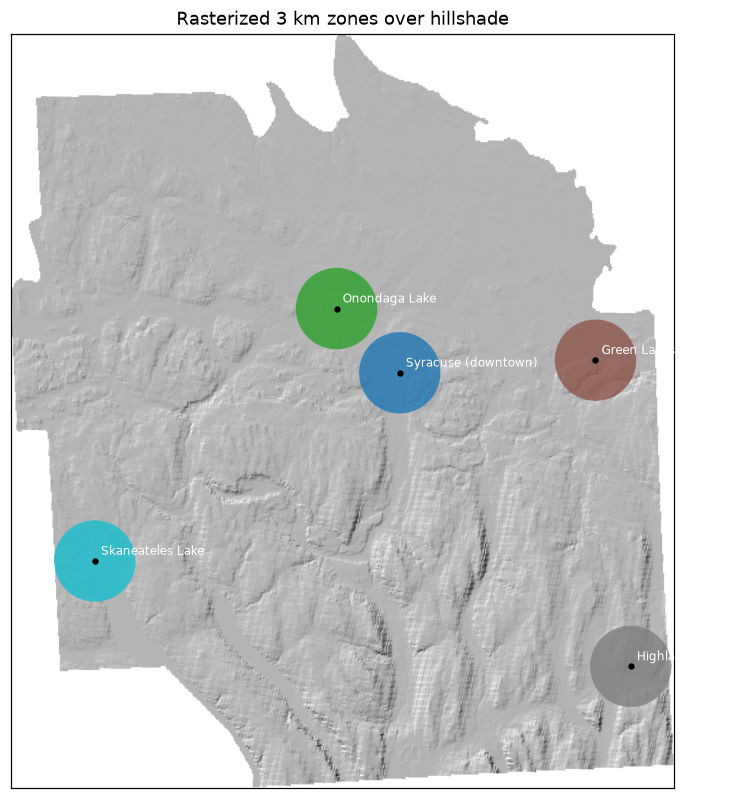

In [ ]:
# Rasterize the buffers so each pixel carries a zone id.
#
# rasterio.features.rasterize burns vector polygons into the NDVI grid.
# Zone 1, 2, 3... are written as integers; pixels outside every buffer stay 0.
# The expected count for one circle is π r² / pixel area, with r = 3000 m and
# 30 m pixels. The figure lays those zone ids over the hillshade.

from rasterio.features import rasterize
# burn the buffers into a raster: zone number per pixel
burned = rasterize(((g, i + 1) for i, g in enumerate(zones.geometry)), out_shape=ndvi.shape,
                   transform=ndvi.rio.transform(), fill=0, dtype="int16")
# pixels per zone
print("Pixels per zone:", {s: int(n) for s, n in zip(zones.site, np.bincount(burned.ravel())[1:])},
      f"| a 3 km circle holds π·3000²/30² ≈ {np.pi * 3000**2 / 900:.0f} pixels")
xmin, ymin, xmax, ymax = hill.rio.bounds()  # extent of the hillshade
fig, ax = plt.subplots(figsize=(7, 8))  # one panel
ax.imshow(hill.values, cmap="gray", extent=[xmin, xmax, ymin, ymax])  # hillshade background
# zones in colour
ax.imshow(np.where(burned > 0, burned, np.nan), cmap="tab10", alpha=0.8, extent=[xmin, xmax, ymin, ymax])
sites.plot(ax=ax, color="k", markersize=10)  # the sites
for _, r in sites.iterrows():  # each site
    # its name
    ax.annotate(r.site, (r.geometry.x, r.geometry.y), xytext=(4, 4), textcoords="offset points", fontsize=8, color="w")
ax.set_title("Rasterized 3 km zones over hillshade"); ax.set_xticks([]); ax.set_yticks([])  # title, no ticks
plt.tight_layout(); plt.show()  # arrange and draw

## Visualization and contrast stretching


Satellite values rarely fill the display range, so images look dark or washed out without a
**contrast stretch**. `rs.viz.rgb` builds composites from preset band combinations and supports
several stretches:

- `percentile` (default 2-98 %): robust to outliers; the usual choice.
- `minmax`: full data range; sensitive to a few extreme pixels.
- `std`: mean ± *n* standard deviations.
- `equalize`: histogram equalization; maximizes contrast but distorts colours.


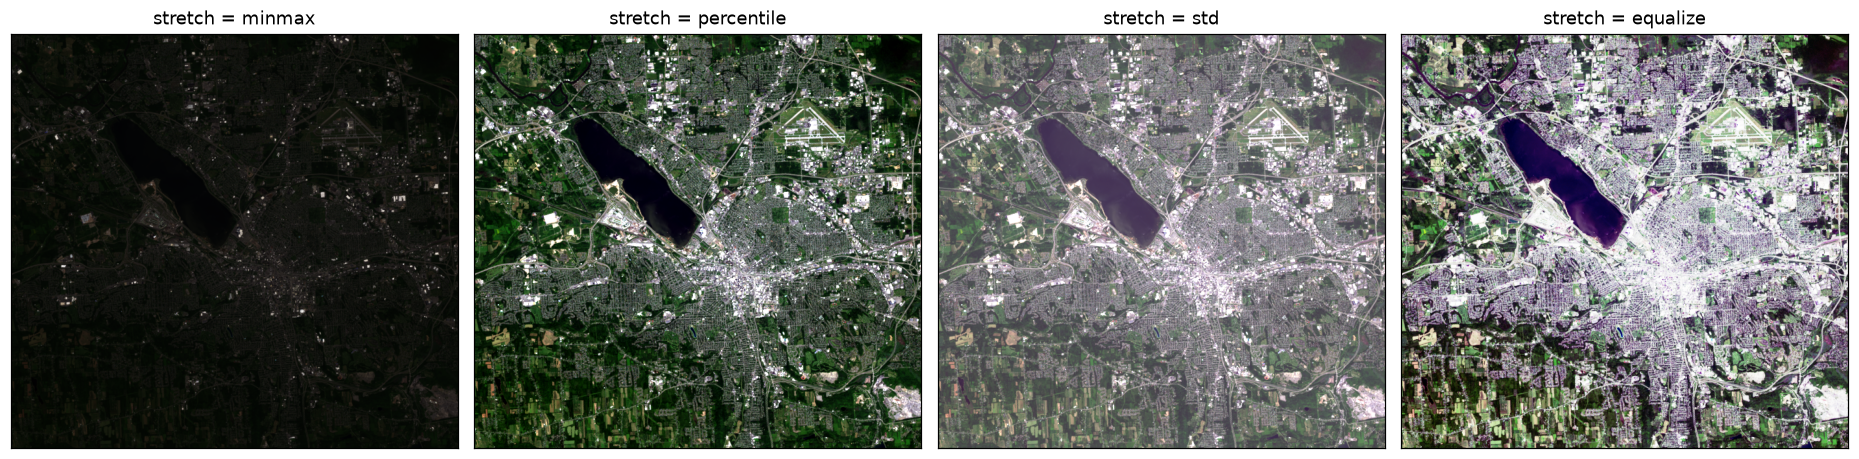

In [ ]:
# Compare four ways to stretch a true-colour image for display.
#
# Satellite reflectance rarely fills 0-1, so an unstretched RGB looks dark or
# washed out. rgb(..., method=...) rescales values for drawing only:
#   minmax: stretch from the minimum to the maximum (a few bright roofs dominate)
#   percentile: ignore the darkest and brightest tails
#   std: stretch around the mean by a number of standard deviations
#   equalize: spread values so each brightness level is used about equally
# The underlying reflectance array is not changed.

scene = ls.rio.clip_box(*aoi.to_crs(landsat.rio.crs).total_bounds)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))  # four panels
for a, m in zip(axes, ["minmax", "percentile", "std", "equalize"]):  # four contrast stretches
    # natural colour with that stretch
    rs.viz.plot_rgb(rs.viz.rgb(scene, "true_color", method=m), ax=a, title=f"stretch = {m}")
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

`minmax` leaves the image nearly black, because a few very bright roofs set the maximum.
`percentile` (2-98%) gives a natural-looking image. `std` is greyer and lower in contrast.
`equalize` maximizes contrast everywhere but gives water and the city a purple cast, so it
is useful for interpretation but not for presentation.

The Sentinel-2 scene stores reflectance ×10,000. Scaling it to 0-1 lets us compute indices
correctly and compare composites at 10 m resolution:


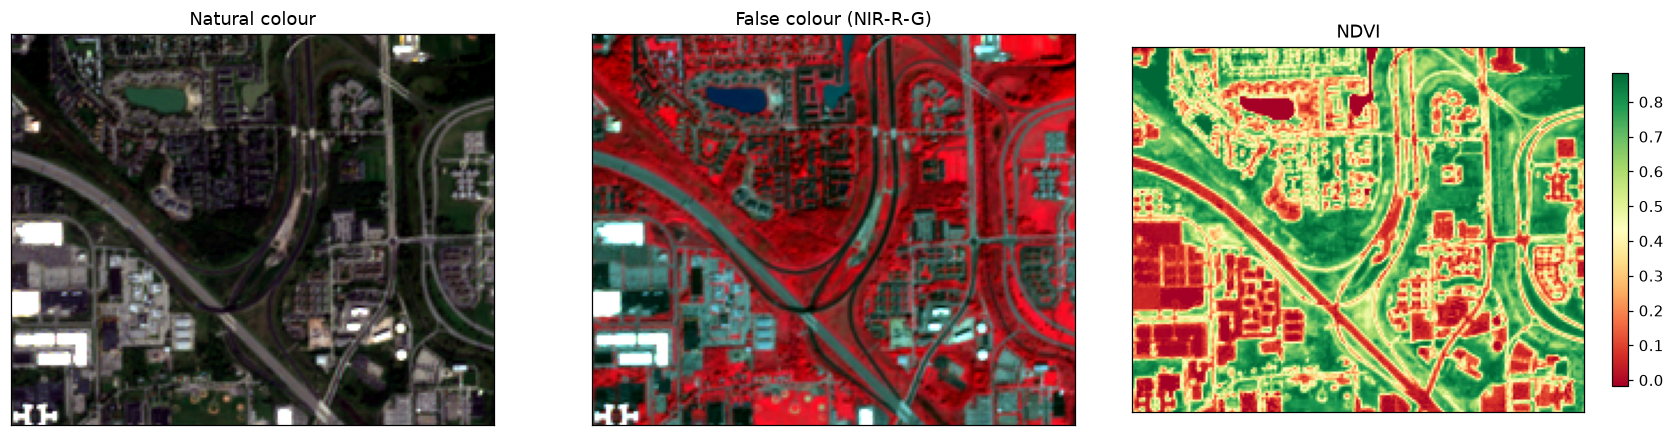

In [ ]:
# Build a Sentinel-2 dataset from separate single-band GeoTIFFs.
#
# Each file is one band stored as digital numbers. Dividing by 10,000 converts
# those integers to surface reflectance (the Sentinel-2 scaling). The files have
# no CRS tag, so EPSG:32617 is attached from the scene documentation.
# The three panels are natural colour, false colour (vegetation in red), and NDVI.

S2_BANDS = {"B2": "blue", "B3": "green", "B4": "red", "B8": "nir"}
# Sentinel-2 bands as reflectance (DN / 10,000)
s2r = xr.Dataset({name: rs.read(S2_DIR / f"{b}.tif").squeeze("band", drop=True) / 10_000
                  for b, name in S2_BANDS.items()}).rio.write_crs("EPSG:32617")
s2_ndvi = rs.optical.index(s2r, "NDVI")  # NDVI
fig, axes = plt.subplots(1, 3, figsize=(16, 4))  # three panels
rs.viz.plot_rgb(s2r, "true_color", ax=axes[0], title="Natural colour")  # natural colour
rs.viz.plot_rgb(s2r, ("nir", "red", "green"), ax=axes[1], title="False colour (NIR-R-G)")  # false colour
rs.viz.plot_raster(s2_ndvi, ax=axes[2], cmap="RdYlGn", title="NDVI")  # NDVI
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

In [ ]:
# Save the products this notebook computed.
#
# NDVI and hillshade go out as GeoTIFFs (rs.write keeps the CRS and transform).
# The site points go out as a GeoPackage, which holds the geometry and the
# elevation/NDVI columns sampled above. The print lists everything now in outputs/.

rs.write(ndvi, OUT / "ndvi_onondaga_utm.tif")
rs.write(hill.astype("float32"), OUT / "hillshade_onondaga_utm.tif")  # save the hillshade as GeoTIFF
sites.to_file(OUT / "sites.gpkg", driver="GPKG")  # save the sites as GeoPackage
print(sorted(p.name for p in OUT.iterdir()))  # list the output folder

['hillshade_onondaga_utm.tif', 'ndvi_onondaga_utm.tif', 'nir.nc', 'nir.zarr', 'nir_cog.tif', 'sites.gpkg']


## Summary and exercises


**Key ideas**

- Always inspect CRS, resolution, data type and no-data before analysis. A missing CRS must
  be *assigned* from documentation before anything else.
- Use COG for sharing single rasters, Zarr for large cubes, NetCDF for gridded science data.
- Reproject to a projected CRS for distances and areas; use `nearest` for classes and
  `bilinear`/`average` for continuous data; put layers on one grid with `reproject_match`.
- Clip and read windows to stay within memory; mosaic tiles with explicit overlap rules.
- Zonal statistics and point extraction link rasters to field data and administrative units.

**Exercises**

1. Reproject the Landsat reflectance to Web Mercator with `nearest` and `cubic` resampling
   and compare NDVI histograms with the original UTM NDVI.
2. Clip the Landsat scene to a polygon around Onondaga Lake and estimate the lake area from
   NDVI < 0 pixels (in km²). Compare with the published area (about 12 km²).
3. Mosaic the four DEM tiles with `"mean"` after making them overlap by 20 pixels and adding
   +10 m to one tile. Where does the seam appear?
4. Compute zonal statistics of slope for the five sites. Which is steepest?
5. Make an "agriculture" composite of the Sentinel-2 scene using other bands (for example
   B11, B8, B2) and different stretches, and describe what each reveals.
6. Use the county layer to clip the Landsat scene to the neighbouring Madison or Cayuga
   County. What happens, and why?

**Next:** Notebook 09_01_03 finds and loads imagery from STAC catalogs, NASA Earthdata, Copernicus,
ASF and Earth Engine, and builds lazy data cubes.
